In [4]:
# ============================================================
# CELL 1 (01_eda_data_audit): Setup, load cleaned data, quick overview
# What it does:
#   - imports libraries and sets paths (same layout as notebook 00)
#   - loads stations_clean.parquet and stations_flags.parquet
#   - defines station metadata (index, lat, lon, elevation) and saves
#     it to data/processed/station_meta.csv for later notebooks
#   - defines the season mapping (pre-monsoon Mar-May, monsoon Jun-Sep,
#     post-monsoon Oct-Nov, winter Dec-Feb) and a wet-day threshold
#     (1 mm) to be used throughout the EDA
#   - prints a per-station overview: % valid days, wet-day fraction,
#     mean annual total (years with >= 350 valid days) and mean
#     monsoon share of the annual total
# ============================================================
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 150)
sns.set_theme(style="whitegrid", context="notebook")

ROOT = Path.cwd().parent
DATA_DIR = ROOT / "data"
PROCESSED_DIR = DATA_DIR / "processed"
OUTPUT_DIR = ROOT / "outputs"
(OUTPUT_DIR / "eda").mkdir(parents=True, exist_ok=True)

clean = pd.read_parquet(PROCESSED_DIR / "stations_clean.parquet")
flags = pd.read_parquet(PROCESSED_DIR / "stations_flags.parquet")
stations = list(clean.columns)

# --- station metadata ---
meta = pd.DataFrame({
    "station": ["Pokhara Airport", "Kunchha", "Bandipur", "Lumle", "Damauli", "Sikles", "Lamachaur"],
    "index":   ["0804", "0807", "0808", "0814", "0817", "0824", "0818"],
    "lat":     [28.188621, 28.12677778, 27.94183333, 28.29653889, 27.973675, 28.355852, 28.261298],
    "lon":     [84.0169252, 84.34494167, 84.40637778, 83.81791111, 84.26509167, 84.102068, 83.968287],
    "elev_m":  [804, 820, 991, 1738, 347, 1967, 991],
}).set_index("station").loc[stations]
meta.to_csv(PROCESSED_DIR / "station_meta.csv")

# --- seasons and wet-day threshold ---
SEASON_OF_MONTH = {12: "Winter", 1: "Winter", 2: "Winter",
                   3: "Pre-monsoon", 4: "Pre-monsoon", 5: "Pre-monsoon",
                   6: "Monsoon", 7: "Monsoon", 8: "Monsoon", 9: "Monsoon",
                   10: "Post-monsoon", 11: "Post-monsoon"}
SEASONS = ["Winter", "Pre-monsoon", "Monsoon", "Post-monsoon"]
WET = 1.0   # mm

season = clean.index.month.map(SEASON_OF_MONTH)

# --- overview ---
yr_count = clean.groupby(clean.index.year).count()
yr_sum = clean.groupby(clean.index.year).sum(min_count=1).where(yr_count >= 350)
mon_df = clean.loc[clean.index.month.isin([6, 7, 8, 9])]
mons = mon_df.groupby(mon_df.index.year).sum(min_count=1)
mons_share = (mons / yr_sum).mean()

overview = pd.DataFrame({
    "valid_%": (100 * clean.notna().mean()).round(1),
    "wet_day_frac_%": (100 * (clean >= WET).sum() / clean.notna().sum()).round(1),
    "mean_annual_mm": yr_sum.mean().round(0),
    "years_used": yr_sum.notna().sum(),
    "monsoon_share_%": (100 * mons_share).round(0),
    "elev_m": meta["elev_m"],
})
print("Clean table:", clean.shape, "|", clean.index.min().date(), "->", clean.index.max().date())
print("\nStation overview:")
print(overview.to_string())
print("\nSaved: data/processed/station_meta.csv")

Clean table: (14975, 7) | 1983-01-01 -> 2023-12-31

Station overview:
                 valid_%  wet_day_frac_%  mean_annual_mm  years_used  monsoon_share_%  elev_m
Pokhara Airport    100.0            39.4          3888.0          41             79.0     804
Kunchha             98.1            27.0          2610.0          32             77.0     820
Bandipur            90.4            26.3          1950.0          29             74.0     991
Lumle               99.6            46.6          5443.0          39             85.0    1738
Damauli             95.1            26.4          1820.0          26             74.0     347
Sikles              99.8            50.0          3817.0          40             74.0    1967
Lamachaur           95.7            40.4          4373.0          34             82.0     991

Saved: data/processed/station_meta.csv


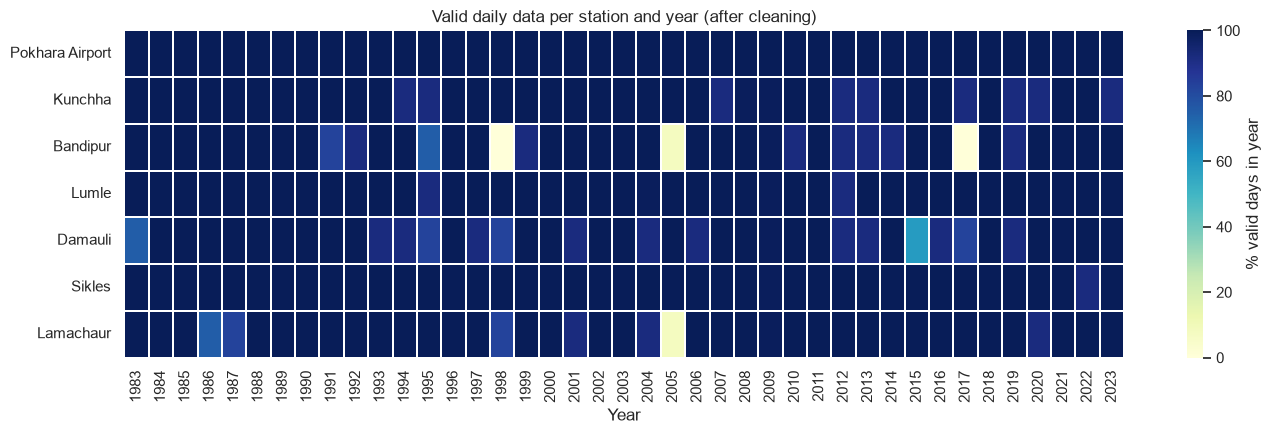

% of days missing, by season:
                 Winter  Pre-monsoon  Monsoon  Post-monsoon
Pokhara Airport     0.0          0.0      0.0           0.0
Kunchha             1.8          1.6      0.6           5.0
Bandipur            7.4          9.0      8.5          15.9
Lumle               0.9          0.8      0.0           0.0
Damauli             5.7          4.1      1.2          12.4
Sikles              0.1          0.8      0.0           0.0
Lamachaur           5.8          2.5      3.7           6.1

Gap structure per station:

Pokhara Airport: 0 gaps, 0 missing days

Kunchha: 11 gaps, 280 missing days
    (31, '2020-12-01', '2020-12-31')
    (31, '2019-10-01', '2019-10-31')
    (31, '2017-10-01', '2017-10-31')
    (31, '2012-10-01', '2012-10-31')

Bandipur: 15 gaps, 1435 missing days
    (365, '2017-01-01', '2017-12-31')
    (365, '1998-01-01', '1998-12-31')
    (334, '2005-02-01', '2005-12-31')
    (61, '1995-11-01', '1995-12-31')

Lumle: 5 gaps, 66 missing days
    (31, '2012-0

In [5]:
# ============================================================
# CELL 2 (01_eda_data_audit): Missing-data pattern
# What it does:
#   - draws a heatmap of % valid days per station and year
#     (stations on the y-axis, years on the x-axis) and saves it to
#     outputs/eda/missing_by_year.png
#   - prints the % of missing days per season for each station, to
#     show whether gaps cluster in the monsoon
#   - prints, per station, the number of separate gaps and the 4
#     longest ones (days, start, end)
# ============================================================
# --- heatmap: % valid days per year ---
valid_pct = clean.notna().groupby(clean.index.year).mean().mul(100).round(0)

fig, ax = plt.subplots(figsize=(14, 4.5))
sns.heatmap(valid_pct.T, cmap="YlGnBu", vmin=0, vmax=100,
            linewidths=0.3, linecolor="white",
            cbar_kws={"label": "% valid days in year"}, ax=ax)
ax.set_title("Valid daily data per station and year (after cleaning)")
ax.set_xlabel("Year")
ax.set_ylabel("")
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "eda" / "missing_by_year.png", dpi=150)
plt.show()

# --- missing share by season ---
season_arr = np.asarray(season)
miss = clean.isna()
miss_days = miss.groupby(season_arr).sum().loc[SEASONS]
tot_days = pd.Series(season_arr).value_counts().loc[SEASONS]
pct_missing = miss_days.div(tot_days, axis=0).mul(100).round(1)
print("% of days missing, by season:")
print(pct_missing.T.to_string())

# --- gap structure ---
def nan_runs(s):
    n = s.isna()
    grp = (n != n.shift(fill_value=False)).cumsum()
    runs = []
    for _, ch in n.groupby(grp):
        if ch.iloc[0]:
            runs.append((len(ch), ch.index[0].date().isoformat(), ch.index[-1].date().isoformat()))
    return sorted(runs, reverse=True)

print("\nGap structure per station:")
for c in stations:
    runs = nan_runs(clean[c])
    print(f"\n{c}: {len(runs)} gaps, {sum(r[0] for r in runs)} missing days")
    for r in runs[:4]:
        print("   ", r)

Common months per calendar month (all 7 stations valid):
{1: 36, 2: 34, 3: 34, 4: 34, 5: 35, 6: 37, 7: 37, 8: 37, 9: 37, 10: 27, 11: 35, 12: 34}

Monthly climatology, common months (mm):
       Pokhara Airport  Kunchha  Bandipur   Lumle  Damauli  Sikles  Lamachaur
month                                                                        
1                 20.0     18.0      17.0    31.0     17.0    47.0       19.0
2                 38.0     34.0      31.0    56.0     32.0    93.0       36.0
3                 60.0     54.0      37.0    66.0     41.0   147.0       62.0
4                120.0    105.0      81.0   110.0     92.0   196.0      106.0
5                352.0    263.0     214.0   324.0    218.0   323.0      345.0
6                672.0    502.0     366.0   875.0    354.0   606.0      785.0
7                957.0    623.0     474.0  1476.0    428.0   900.0     1083.0
8                827.0    506.0     355.0  1384.0    309.0   843.0      993.0
9                671.0    364.0  

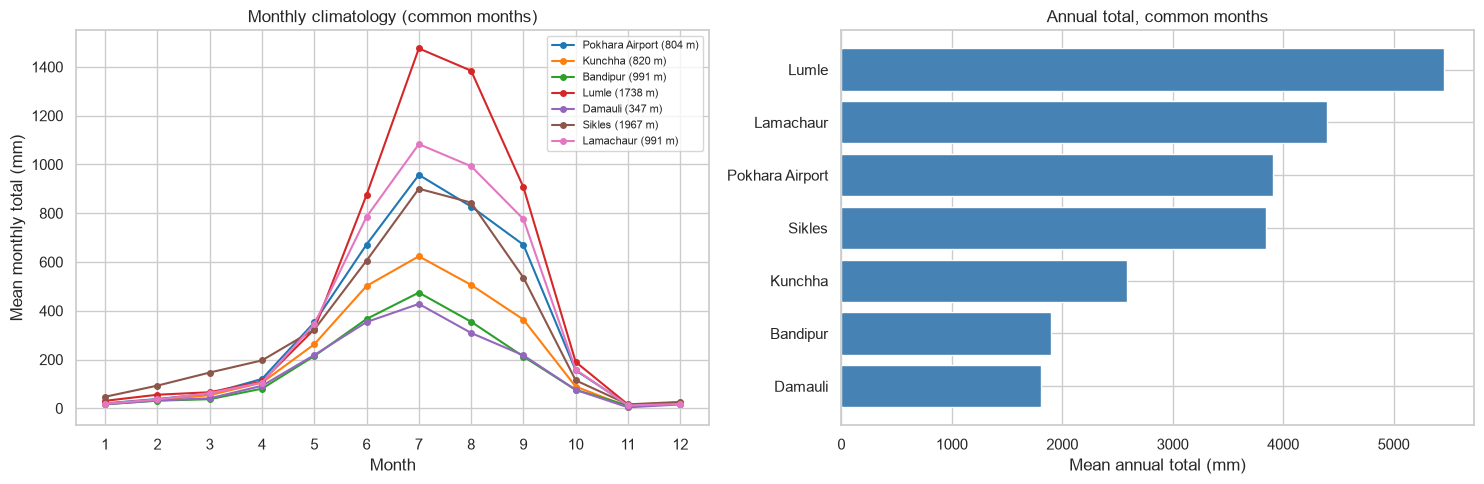

In [6]:
# ============================================================
# CELL 3 (01_eda_data_audit): Monthly and seasonal climatology
# What it does:
#   1) builds monthly totals per station (only months with >= 25 valid
#      days; totals are scaled up to the full month length)
#   2) mean monthly climatology twice: from all available months, and
#      from "common months" where all 7 stations are valid, so that the
#      stations are compared on identical dates
#   3) prints the common-month climatology table (12 months x 7
#      stations), the number of common months per calendar month, and
#      mean annual totals from both methods
#   4) prints per-season totals, wet-day frequency (>= 1 mm) and mean
#      wet-day intensity (mm per wet day)
#   5) plots monthly climatology and annual totals, saves the figure
#      and outputs/eda/monthly_climatology.csv
# ============================================================
ym = [clean.index.year, clean.index.month]
tot = clean.groupby(ym).sum(min_count=1)
cnt = clean.groupby(ym).count()
size = clean.groupby(ym).size()
for obj in (tot, cnt, size):
    obj.index.names = ["year", "month"]

mean_daily = tot / cnt.where(cnt >= 25)
mtot = mean_daily.mul(size, axis=0)          # monthly totals, NaN if < 25 valid days

# --- all-available vs common-month climatology ---
clim_all = mtot.groupby(level="month").mean()
common = mtot.notna().all(axis=1)
clim_common = mtot[common].groupby(level="month").mean()
n_common = common.groupby(level="month").sum()

print("Common months per calendar month (all 7 stations valid):")
print(n_common.to_dict())

print("\nMonthly climatology, common months (mm):")
print(clim_common.round(0).to_string())

cmp_annual = pd.DataFrame({
    "annual_all_available": clim_all.sum().round(0),
    "annual_common_months": clim_common.sum().round(0),
})
cmp_annual["difference"] = cmp_annual["annual_common_months"] - cmp_annual["annual_all_available"]
print("\nMean annual total (mm), two methods:")
print(cmp_annual.to_string())

# --- seasonal statistics ---
season_arr = np.asarray(clean.index.month.map(SEASON_OF_MONTH))
season_tot = clim_common.groupby(clim_common.index.map(SEASON_OF_MONTH)).sum().loc[SEASONS]
wet_freq = ((clean >= WET).astype(float).where(clean.notna())
            .groupby(season_arr).mean().loc[SEASONS] * 100)
intensity = clean.where(clean >= WET).groupby(season_arr).mean().loc[SEASONS]

print("\nSeasonal total (mm), common months:")
print(season_tot.round(0).T.to_string())
print("\nWet-day frequency (% of days >= 1 mm):")
print(wet_freq.round(1).T.to_string())
print("\nMean intensity on wet days (mm/wet day):")
print(intensity.round(1).T.to_string())

# --- plots ---
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
palette = sns.color_palette("tab10", len(stations))
for c, col in zip(stations, palette):
    axes[0].plot(clim_common.index, clim_common[c], marker="o", ms=4, color=col,
                 label=f"{c} ({int(meta.loc[c, 'elev_m'])} m)")
axes[0].set_xticks(range(1, 13))
axes[0].set_xlabel("Month")
axes[0].set_ylabel("Mean monthly total (mm)")
axes[0].set_title("Monthly climatology (common months)")
axes[0].legend(fontsize=8)

ann = cmp_annual["annual_common_months"].sort_values()
axes[1].barh(ann.index, ann.values, color="steelblue")
axes[1].set_xlabel("Mean annual total (mm)")
axes[1].set_title("Annual total, common months")
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "eda" / "monthly_climatology.png", dpi=150)
plt.show()

clim_common.round(1).to_csv(OUTPUT_DIR / "eda" / "monthly_climatology.csv")

Distance between stations (km):
                 Pokhara Airport  Kunchha  Bandipur  Lumle  Damauli  Sikles  Lamachaur
Pokhara Airport                0       33        47     23       34      20          9
Kunchha                       33        0        21     55       19      35         40
Bandipur                      47       21         0     70       14      55         56
Lumle                         23       55        70      0       57      29         15
Damauli                       34       19        14     57        0      45         43
Sikles                        20       35        55     29       45       0         17
Lamachaur                      9       40        56     15       43      17          0

Spearman correlation of daily rainfall by season (pairs sorted by distance):
                       pair  dist_km  Winter  Pre-monsoon  Monsoon  Post-monsoon
Pokhara Airport - Lamachaur        9    0.66         0.70     0.64          0.70
         Bandipur - Damauli     

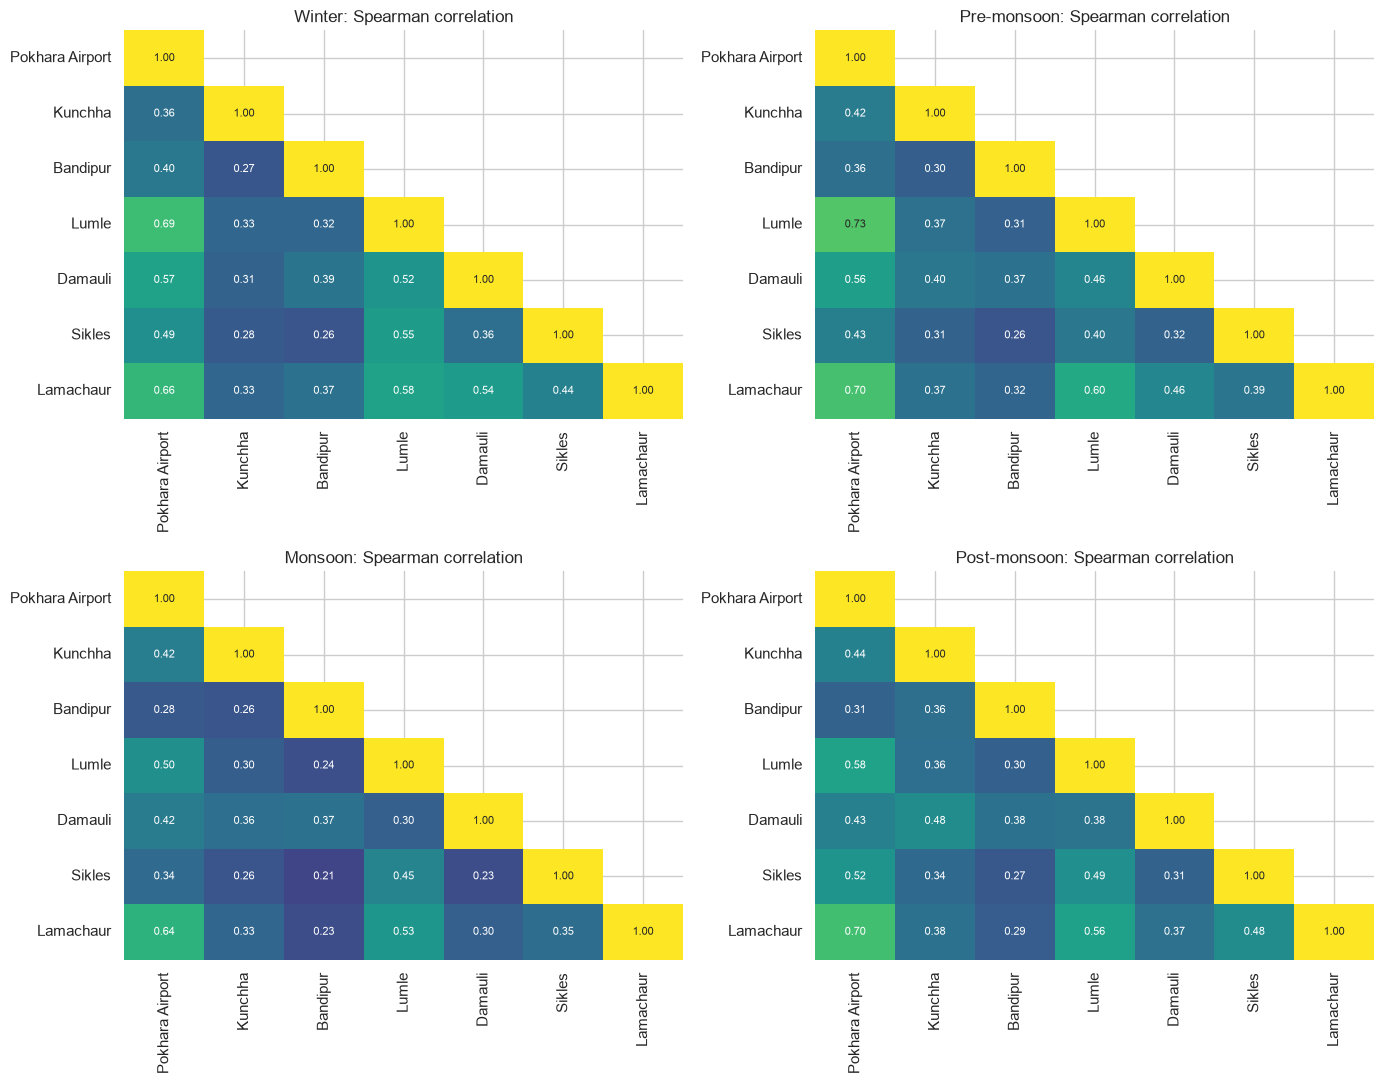

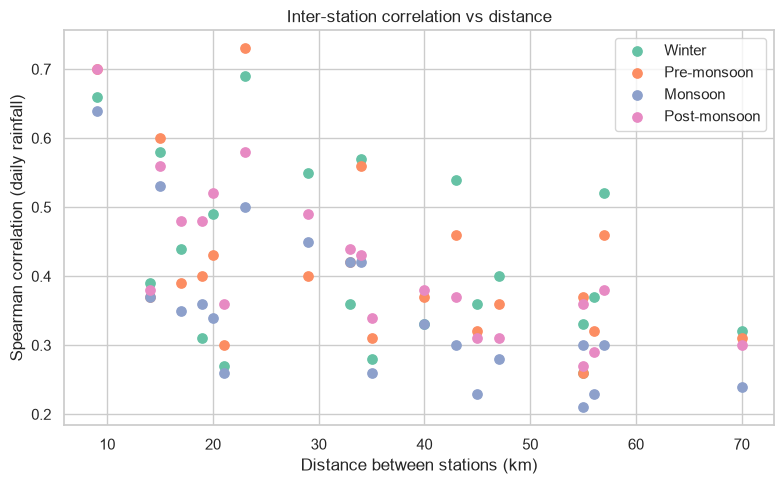

In [7]:
# ============================================================
# CELL 4 (01_eda_data_audit): Inter-station correlation and lag check
# What it does:
#   1) computes great-circle distances between all station pairs (km)
#   2) computes Spearman rank correlations of daily rainfall per
#      season, using days where both stations are valid (rank
#      correlation is robust to the heavy skew; note that many ties
#      at zero mean it partly measures wet/dry agreement)
#   3) prints a table of all 21 pairs sorted by distance with the four
#      seasonal correlations
#   4) lag test (monsoon only): correlation of station A on day t with
#      station B on day t-1, t, t+1. If lag +1 or -1 beats lag 0 for a
#      pair, one of the two stations is probably shifted by a day
#   5) saves two figures (seasonal heatmaps; correlation vs distance)
#      and the pair table to outputs/eda/
# ============================================================
from itertools import combinations

# --- 1) distances ---
R = 6371.0
lat = np.radians(meta["lat"].values)
lon = np.radians(meta["lon"].values)
dlat = lat[:, None] - lat[None, :]
dlon = lon[:, None] - lon[None, :]
a = (np.sin(dlat / 2) ** 2
     + np.cos(lat)[:, None] * np.cos(lat)[None, :] * np.sin(dlon / 2) ** 2)
dist = pd.DataFrame(2 * R * np.arcsin(np.sqrt(a)), index=stations, columns=stations)
print("Distance between stations (km):")
print(dist.round(0).astype(int).to_string())

# --- 2) seasonal Spearman matrices ---
season_s = pd.Series(np.asarray(clean.index.month.map(SEASON_OF_MONTH)), index=clean.index)
corr = {s: clean[season_s == s].corr(method="spearman", min_periods=100) for s in SEASONS}

# --- 3) pair table ---
rows = []
for p, q in combinations(stations, 2):
    r = {"pair": f"{p} - {q}", "dist_km": int(round(dist.loc[p, q]))}
    for s in SEASONS:
        r[s] = round(corr[s].loc[p, q], 2)
    rows.append(r)
pairs = pd.DataFrame(rows).sort_values("dist_km").reset_index(drop=True)
print("\nSpearman correlation of daily rainfall by season (pairs sorted by distance):")
print(pairs.to_string(index=False))
pairs.to_csv(OUTPUT_DIR / "eda" / "pair_correlations.csv", index=False)

# --- 4) lag test, monsoon only ---
mons_mask = season_s == "Monsoon"
lag_rows = []
for p, q in combinations(stations, 2):
    row = {"pair": f"{p} - {q}"}
    for k in (-1, 0, 1):
        y = clean[q].shift(-k)          # value of q on day t+k
        row[f"lag{k:+d}"] = round(clean[p][mons_mask].corr(y[mons_mask], method="spearman"), 2)
    row["best"] = max(("lag-1", "lag+0", "lag+1"), key=lambda c: row[c])
    lag_rows.append(row)
lag_df = pd.DataFrame(lag_rows)
print("\nMonsoon lag test (A on day t vs B on day t+k):")
print(lag_df.to_string(index=False))
print("\nPairs where best lag is not 0:", lag_df[lag_df["best"] != "lag+0"]["pair"].tolist())

# --- 5) figures ---
fig, axes = plt.subplots(2, 2, figsize=(14, 11))
tri = np.triu(np.ones((len(stations), len(stations)), dtype=bool), k=1)
for ax, s in zip(axes.ravel(), SEASONS):
    sns.heatmap(corr[s], mask=tri, annot=True, fmt=".2f", vmin=0, vmax=1,
                cmap="viridis", cbar=False, ax=ax, annot_kws={"size": 8})
    ax.set_title(f"{s}: Spearman correlation")
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "eda" / "correlation_heatmaps.png", dpi=150)
plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
for s, col in zip(SEASONS, sns.color_palette("Set2", 4)):
    ax.scatter(pairs["dist_km"], pairs[s], label=s, color=col, s=45)
ax.set_xlabel("Distance between stations (km)")
ax.set_ylabel("Spearman correlation (daily rainfall)")
ax.set_title("Inter-station correlation vs distance")
ax.legend()
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "eda" / "correlation_vs_distance.png", dpi=150)
plt.show()

1) Annual maximum 1-day rainfall (mm):
        station  years  Rx1day_mean  Rx1day_median  Rx1day_max  year_of_max
Pokhara Airport     41        198.0          187.0       357.0         2001
        Kunchha     32        148.0          141.0       215.8         2000
       Bandipur     29        109.0          102.0       200.2         2003
          Lumle     39        204.0          192.0       308.3         2017
        Damauli     26        123.0          121.0       223.0         2022
         Sikles     40        145.0          139.0       247.2         1996
      Lamachaur     34        185.0          177.0       314.0         2007

2) Wet-day percentiles (mm) and heavy-day frequency:
        station  wet_days  P90   P95   P99   max  days>=50/yr  days>=100/yr  days>=150/yr
Pokhara Airport      5899 66.4  93.5 160.0 357.0         22.3          5.95          1.93
        Kunchha      3964 60.5  80.5 131.1 215.8         14.7          2.46          0.52
       Bandipur      3565 45.

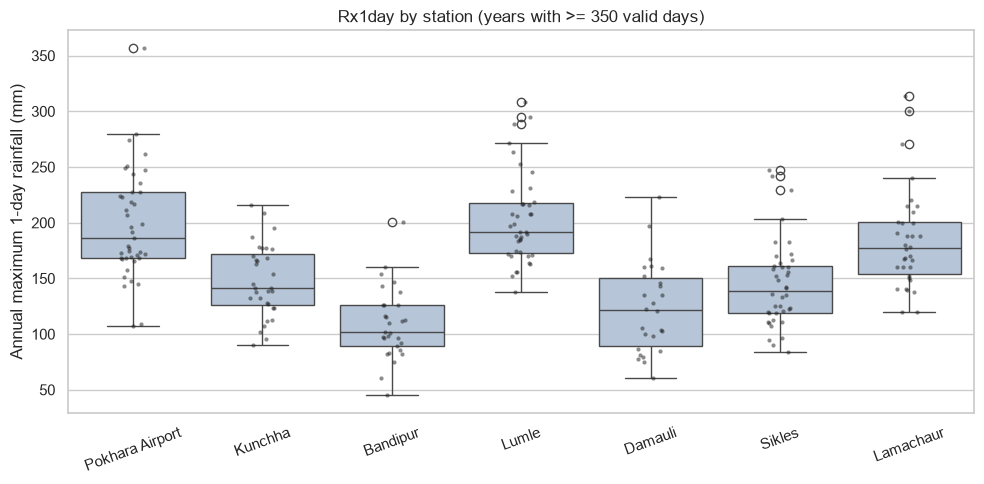

In [8]:
# ============================================================
# CELL 5 (01_eda_data_audit): Extremes and the 2020-2023 trace-value check
# What it does:
#   1) annual maximum 1-day rainfall (Rx1day) per station, using years
#      with >= 350 valid days: mean, median, max and year of max
#   2) wet-day (>= 1 mm) percentiles: P90, P95, P99 and the maximum, and
#      the number of days per year above 50, 100 and 150 mm
#   3) share of total rainfall coming from the heaviest 5% of wet days
#   4) era comparison, 1983-2019 vs 2020-2023: wet-day frequency using
#      >= 0.1 mm and >= 1 mm, share of non-zero values that are whole
#      numbers, and number of trace values (0 < x < 0.1) -- this shows
#      whether the instrument/record changed in 2020
#   5) saves a boxplot of annual Rx1day per station and the extremes
#      table to outputs/eda/
# ============================================================
yr = clean.index.year
cnt_y = clean.groupby(yr).count()
rx1 = clean.groupby(yr).max().where(cnt_y >= 350)

rows = []
for c in stations:
    s = rx1[c].dropna()
    rows.append({"station": c, "years": len(s),
                 "Rx1day_mean": round(s.mean(), 0), "Rx1day_median": round(s.median(), 0),
                 "Rx1day_max": s.max(), "year_of_max": int(s.idxmax())})
print("1) Annual maximum 1-day rainfall (mm):")
print(pd.DataFrame(rows).to_string(index=False))

# --- 2) wet-day percentiles and heavy-day counts ---
rows = []
for c in stations:
    v = clean[c].dropna()
    w = v[v >= WET]
    n_years = len(v) / 365.25
    rows.append({
        "station": c, "wet_days": len(w),
        "P90": round(w.quantile(0.90), 1), "P95": round(w.quantile(0.95), 1),
        "P99": round(w.quantile(0.99), 1), "max": w.max(),
        "days>=50/yr": round((v >= 50).sum() / n_years, 1),
        "days>=100/yr": round((v >= 100).sum() / n_years, 2),
        "days>=150/yr": round((v >= 150).sum() / n_years, 2),
    })
ext_table = pd.DataFrame(rows)
print("\n2) Wet-day percentiles (mm) and heavy-day frequency:")
print(ext_table.to_string(index=False))
ext_table.to_csv(OUTPUT_DIR / "eda" / "extremes_table.csv", index=False)

# --- 3) contribution of the heaviest 5% of wet days ---
share = {}
for c in stations:
    v = clean[c].dropna()
    w = v[v >= WET]
    p95 = w.quantile(0.95)
    share[c] = round(100 * w[w >= p95].sum() / v.sum(), 1)
print("\n3) % of total rainfall from the heaviest 5% of wet days:")
print(pd.Series(share).to_string())

# --- 4) era comparison ---
eras = {"1983-2019": clean.loc[:"2019-12-31"], "2020-2023": clean.loc["2020-01-01":]}
rows = []
for c in stations:
    for name, df in eras.items():
        v = df[c].dropna()
        nz = v[v > 0]
        whole = np.isclose(nz % 1, 0) if len(nz) else np.array([])
        rows.append({
            "station": c, "era": name, "days": len(v),
            "wet>=0.1mm_%": round(100 * (v >= 0.1).mean(), 1),
            "wet>=1mm_%": round(100 * (v >= 1.0).mean(), 1),
            "nonzero_whole_%": round(100 * whole.mean(), 1) if len(nz) else np.nan,
            "trace_count": int(((v > 0) & (v < 0.1)).sum()),
        })
print("\n4) Era comparison (1983-2019 vs 2020-2023):")
print(pd.DataFrame(rows).to_string(index=False))

# --- 5) boxplot ---
fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=rx1[stations], ax=ax, color="lightsteelblue")
sns.stripplot(data=rx1[stations], ax=ax, color="k", size=3, alpha=0.5)
ax.set_ylabel("Annual maximum 1-day rainfall (mm)")
ax.set_title("Rx1day by station (years with >= 350 valid days)")
plt.xticks(rotation=20)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "eda" / "rx1day_boxplot.png", dpi=150)
plt.show()

2) Correlation of annual totals between stations (Pearson, >= 15 common years):
                 Pokhara Airport  Kunchha  Bandipur  Lumle  Damauli  Sikles  Lamachaur
Pokhara Airport             1.00     0.71      0.34   0.69     0.77    0.48       0.67
Kunchha                     0.71     1.00      0.23   0.52     0.55    0.47       0.63
Bandipur                    0.34     0.23      1.00   0.36     0.62    0.38       0.47
Lumle                       0.69     0.52      0.36   1.00     0.58    0.64       0.50
Damauli                     0.77     0.55      0.62   0.58     1.00    0.53       0.69
Sikles                      0.48     0.47      0.38   0.64     0.53    1.00       0.45
Lamachaur                   0.67     0.63      0.47   0.50     0.69    0.45       1.00

3) Trend: Annual total (mm)
                 n_years  per_decade  pct_per_decade      p sig
Pokhara Airport       41       -55.7            -1.4  0.605    
Kunchha               32        83.5             3.2  0.375    
Ban

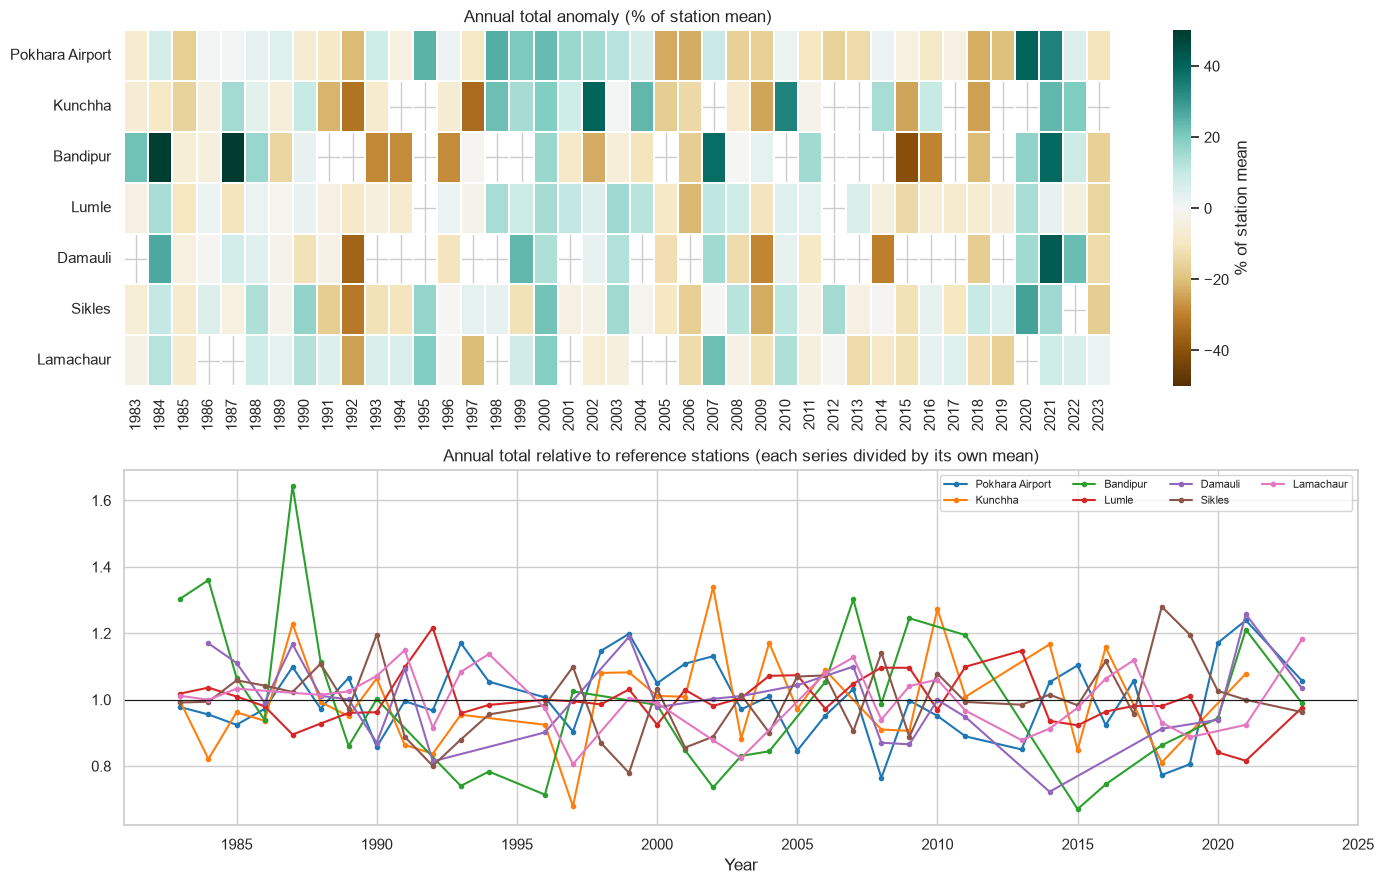

In [9]:
# ============================================================
# CELL 6 (01_eda_data_audit): Year-to-year variability, trends, homogeneity
# What it does:
#   1) builds annual series per station (years with >= 350 valid days):
#      annual total, monsoon (Jun-Sep) total (>= 115 valid days),
#      Rx1day and wet-day frequency (>= 1 mm)
#   2) prints the correlation of annual totals between stations
#      (do they share wet and dry years?)
#   3) Theil-Sen trend per decade and a Mann-Kendall-type p-value
#      (Kendall tau against year) for each series; '*' marks p < 0.05
#   4) homogeneity check: ratio of each station's annual total to the
#      mean of the reference stations (Pokhara Airport, Lumle, Sikles;
#      a reference station is compared with the other two), then a
#      Pettitt test on that ratio for one abrupt shift. Reports the last
#      year before the break, the p-value and the mean ratio before and
#      after
#   5) saves a figure with the annual anomaly heatmap (% of each
#      station's mean) and the normalized ratio series, to
#      outputs/eda/annual_anomalies.png
# ============================================================
from scipy import stats

REF = ["Pokhara Airport", "Lumle", "Sikles"]
yr = clean.index.year
cnt_y = clean.groupby(yr).count()

# --- 1) annual series ---
ann_tot = clean.groupby(yr).sum(min_count=1).where(cnt_y >= 350)
mon_df = clean.loc[clean.index.month.isin([6, 7, 8, 9])]
mon_cnt = mon_df.groupby(mon_df.index.year).count()
mon_tot = mon_df.groupby(mon_df.index.year).sum(min_count=1).where(mon_cnt >= 115)
rx1 = clean.groupby(yr).max().where(cnt_y >= 350)
wetf = ((clean >= WET).astype(float).where(clean.notna())
        .groupby(yr).mean().mul(100).where(cnt_y >= 350))

series = {"Annual total (mm)": ann_tot, "Monsoon total (mm)": mon_tot,
          "Rx1day (mm)": rx1, "Wet-day frequency (%)": wetf}

# --- 2) shared wet/dry years ---
print("2) Correlation of annual totals between stations (Pearson, >= 15 common years):")
print(ann_tot.corr(min_periods=15).round(2).to_string())

# --- 3) trends ---
def trend(s):
    s = s.dropna()
    if len(s) < 15:
        return pd.Series({"n_years": len(s), "per_decade": np.nan,
                          "pct_per_decade": np.nan, "p": np.nan})
    x = s.index.values.astype(float)
    slope = stats.theilslopes(s.values, x)[0]
    p = stats.kendalltau(x, s.values)[1]
    return pd.Series({"n_years": len(s), "per_decade": slope * 10,
                      "pct_per_decade": 100 * slope * 10 / s.mean(), "p": p})

for name, df in series.items():
    t = pd.DataFrame({c: trend(df[c]) for c in stations}).T
    t["n_years"] = t["n_years"].astype(int)
    t["sig"] = np.where(t["p"] < 0.05, "*", "")
    print(f"\n3) Trend: {name}")
    print(t.round({"per_decade": 1, "pct_per_decade": 1, "p": 3}).to_string())

# --- 4) homogeneity: ratio to reference stations + Pettitt test ---
def pettitt(x):
    x = np.asarray(x, float)
    n = len(x)
    U = np.array([np.sign(x[:t + 1, None] - x[None, t + 1:]).sum() for t in range(n - 1)])
    k = int(np.abs(U).argmax())
    K = abs(U[k])
    return k, min(1.0, 2 * np.exp(-6 * K ** 2 / (n ** 3 + n ** 2)))

rows, ratios = [], {}
for c in stations:
    refs = [r for r in REF if r != c]
    ratio = (ann_tot[c] / ann_tot[refs].mean(axis=1, skipna=False)).dropna()
    ratios[c] = ratio
    if len(ratio) < 15:
        continue
    k, p = pettitt(ratio.values)
    rows.append({"station": c, "n_years": len(ratio), "break_after": int(ratio.index[k]),
                 "p": round(p, 3),
                 "mean_ratio_before": round(ratio.iloc[:k + 1].mean(), 3),
                 "mean_ratio_after": round(ratio.iloc[k + 1:].mean(), 3)})
print("\n4) Pettitt test on annual ratio to reference stations:")
print(pd.DataFrame(rows).to_string(index=False))

# --- 5) figure ---
anom = (ann_tot / ann_tot.mean() - 1) * 100
fig, axes = plt.subplots(2, 1, figsize=(14, 9))
sns.heatmap(anom.T, cmap="BrBG", center=0, vmin=-50, vmax=50, ax=axes[0],
            linewidths=0.3, linecolor="white", cbar_kws={"label": "% of station mean"})
axes[0].set_title("Annual total anomaly (% of station mean)")
axes[0].set_xlabel("")
for c, col in zip(stations, sns.color_palette("tab10", len(stations))):
    r = ratios[c]
    axes[1].plot(r.index, r / r.mean(), marker="o", ms=3, color=col, label=c)
axes[1].axhline(1, color="k", lw=0.8)
axes[1].set_title("Annual total relative to reference stations (each series divided by its own mean)")
axes[1].set_xlabel("Year")
axes[1].legend(ncol=4, fontsize=8)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "eda" / "annual_anomalies.png", dpi=150)
plt.show()

In [10]:
# ============================================================
# CELL 7 (01_eda_data_audit): Save the EDA decisions (rulebook for notebook 03)
# What it does:
#   1) computes station-specific extreme thresholds (P95 and P99 of wet
#      days, >= 1 mm) from the full cleaned record
#   2) builds the distance-blocked table: for each held-out station, the
#      training stations that remain once everything within BLOCK_KM is
#      removed, and the distance to the nearest remaining one
#   3) writes all modelling rules to data/processed/eda_decisions.json
#   4) prints the thresholds, the blocked table and the saved rules
# Uses dist, clean, stations, WET and SEASON_OF_MONTH from earlier cells.
# ============================================================
import json

BLOCK_KM = 30

# --- 1) extreme thresholds ---
thr = {}
for c in stations:
    v = clean[c].dropna()
    w = v[v >= WET]
    thr[c] = {"P95_wet": round(float(w.quantile(0.95)), 1),
              "P99_wet": round(float(w.quantile(0.99)), 1)}
print("1) Extreme thresholds (mm):")
print(pd.DataFrame(thr).T.to_string())

# --- 2) distance-blocked training sets ---
block_rows, block_dict = [], {}
for c in stations:
    left = [s for s in stations if s != c and dist.loc[c, s] >= BLOCK_KM]
    block_dict[c] = left
    block_rows.append({
        "held_out": c,
        "n_train_stations": len(left),
        "nearest_train_km": int(round(min(dist.loc[c, s] for s in left))) if left else None,
        "train_stations": ", ".join(left),
    })
print(f"\n2) Distance-blocked training sets (radius {BLOCK_KM} km):")
print(pd.DataFrame(block_rows).to_string(index=False))

# --- 3) rulebook ---
decisions = {
    "modelling_period": ["1983-01-01", "2023-12-31"],
    "wet_day_mm": WET,
    "trace_rule": "values below 0.1 mm are set to 0 in the model table",
    "seasons": {int(k): v for k, v in SEASON_OF_MONTH.items()},
    "missing_data": "masked days stay NaN; drop rows with NaN target; keep NaN in features",
    "flagged_days": "kept; optional sensitivity run without them",
    "spatial_split": {"scheme": "leave-one-station-out plus distance-blocked",
                      "block_km": BLOCK_KM,
                      "blocked_train_stations": block_dict},
    "temporal_split": {"train": ["1983-01-01", "2010-12-31"],
                       "test": ["2011-01-01", "2023-12-31"],
                       "note": "headline score = held-out station and held-out period; tuning inside train years only"},
    "neighbor_features": f"only stations at least {BLOCK_KM} km from the target",
    "extreme_thresholds_mm": thr,
    "fixed_extreme_threshold_mm": 50,
    "report_separately": ["Bandipur"],
    "targets_to_compare": ["raw amount", "residual vs satellite"],
}
with open(PROCESSED_DIR / "eda_decisions.json", "w") as f:
    json.dump(decisions, f, indent=2)

# --- 4) confirm ---
print("\n3) Saved data/processed/eda_decisions.json, keys:")
print(list(decisions.keys()))

1) Extreme thresholds (mm):
                 P95_wet  P99_wet
Pokhara Airport     93.5    160.0
Kunchha             80.5    131.1
Bandipur            63.6    108.4
Lumle              108.5    166.0
Damauli             64.0    110.3
Sikles              70.2    109.3
Lamachaur          100.0    160.0

2) Distance-blocked training sets (radius 30 km):
       held_out  n_train_stations  nearest_train_km                            train_stations
Pokhara Airport                 3                33                Kunchha, Bandipur, Damauli
        Kunchha                 4                33 Pokhara Airport, Lumle, Sikles, Lamachaur
       Bandipur                 4                47 Pokhara Airport, Lumle, Sikles, Lamachaur
          Lumle                 3                55                Kunchha, Bandipur, Damauli
        Damauli                 4                34 Pokhara Airport, Lumle, Sikles, Lamachaur
         Sikles                 3                35                Kunchha, Bandipur,